In [7]:
# import libraries from tutorial
import matplotlib.pyplot as plt
import pandas as pd #package that does dataframes 
import numpy as np

In [8]:
filtered_will = pd.read_csv('../filtered_catalogue_will.csv') #right click file and copy relative path since HarrisPartI.csv is inside a folder # needs TWO!?!? . infront of file
print(filtered_will) # doing this to visualise what I have

    quantity     cluster_id   preferred_name   NGC    matched_to_harris  \
0   NGC 104      NGC 104      47 Tuc           104    True                
1   NGC 288      NGC 288      NGC 288          288    True                
2   NGC 362      NGC 362      NGC 362          362    True                
3   NGC 1261     NGC 1261     NGC 1261         1261   True                
4   NGC 1851     NGC 1851     NGC 1851         1851   True                
..         ...          ...              ...    ...                 ...   
58  NGC 6981     NGC 6981     M 72             6981   True                
59  NGC 7078     NGC 7078     M 15             7078   True                
60  NGC 7089     NGC 7089     M 2              7089   True                
61  NGC 7099     NGC 7099     M 30             7099   True                
62  Pal 12       Pal 12       Pal 12                  True                

     ID         Name     RA            DEC           L       ...   Age  .1  \
0    NGC 104    47 Tu

In [9]:
filtered_will.columns = filtered_will.columns.str.strip()

In [10]:
filtered_x = filtered_will['X'] # take the x component 
filtered_z = filtered_will['Z'] # take the y component

/var/folders/f4/st716v0s7xx87h16gcs77fdr0000gn/T/ipykernel_63766/313402221.py:2: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  zx = axes.scatter(filtered_x, filtered_z, marker='o', s=40, cmap='viridis') # plot components


Text(0, 0.5, '$Z$, $kpc$')

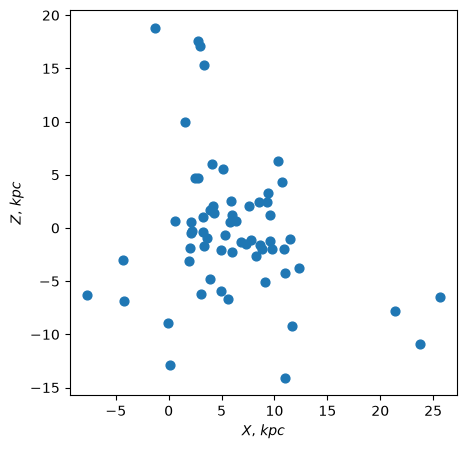

In [11]:
fig, axes = plt.subplots(1, figsize=(5,5)) #I only need one plot
zx = axes.scatter(filtered_x, filtered_z, marker='o', s=40, cmap='viridis') # plot components
axes.set_xlabel('$X$, $kpc$') # x-axis label
axes.set_ylabel('$Z$, $kpc$') # y-axis label

36 points below the line


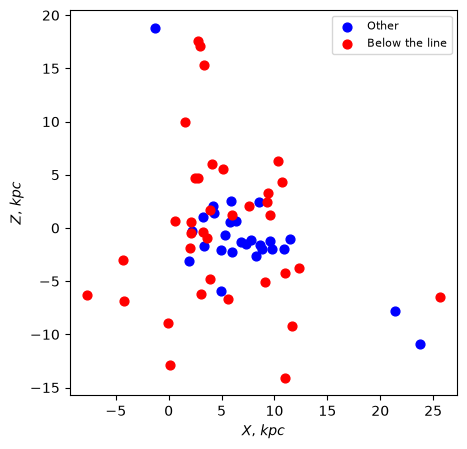

In [ ]:

def model(x, a, b, c):
    return c - a * np.exp(b * x)

a, b, c = 11.6, 1.22, 14.6
xmin, xmax = -2.4, -0.48    

feh = pd.to_numeric(filtered_will['FeH'], errors='coerce')
age = pd.to_numeric(filtered_will['Age'], errors='coerce')

valid = feh.notna() & age.notna() & (age > 0)   
below = valid & (age < model(feh, a, b, c)) & feh.between(xmin, xmax)
mask = below.to_numpy()
print(mask.sum(), "points below the line")


x = np.asarray(filtered_x, dtype=float)
z = np.asarray(filtered_z, dtype=float)

fig, axes = plt.subplots(1, figsize=(5, 5))
axes.scatter(x[~mask], z[~mask], color='blue', s=40, label='Other')
axes.scatter(x[mask], z[mask], color='red', s=40, label='Below the line')
axes.set_xlabel('$X$, $kpc$')
axes.set_ylabel('$Z$, $kpc$')
axes.legend(fontsize=8);